In [1]:
import os
import json
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split

import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:

DATASET_DIR = Path("../data/archive/images")

MODEL_DIR = Path(r"..\models")

MODEL_DIR.mkdir(exist_ok=True)

print(DATASET_DIR)

TRAIN_DIR = DATASET_DIR.parent / "train"
VAL_DIR = DATASET_DIR.parent / "validation"
TEST_DIR = DATASET_DIR.parent / "test"

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)

BATCH_SIZE = 32

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

SEED = 42

..\data\archive\images


In [4]:
image_paths = []
labels = []

classes = sorted([
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

print("Number of classes:", len(classes))

Number of classes: 30


In [5]:
for class_name in classes:

    class_folder = DATASET_DIR / class_name

    for subfolder in class_folder.iterdir():

        if not subfolder.is_dir():
            continue

        for image in subfolder.glob("*.png"):

            image_paths.append(str(image))
            labels.append(class_name)

print("Total Images:", len(image_paths))

Total Images: 15000


In [6]:
df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df.head()

,image_path,label
0,..\data\archive\images\aerosol_cans\default\Im...,aerosol_cans
1,..\data\archive\images\aerosol_cans\default\Im...,aerosol_cans
2,..\data\archive\images\aerosol_cans\default\Im...,aerosol_cans
3,..\data\archive\images\aerosol_cans\default\Im...,aerosol_cans
4,..\data\archive\images\aerosol_cans\default\Im...,aerosol_cans


In [7]:
class_counts = df["label"].value_counts()

print(class_counts)

label
aerosol_cans                  500
aluminum_food_cans            500
aluminum_soda_cans            500
cardboard_boxes               500
cardboard_packaging           500
clothing                      500
coffee_grounds                500
disposable_plastic_cutlery    500
eggshells                     500
food_waste                    500
glass_beverage_bottles        500
glass_cosmetic_containers     500
glass_food_jars               500
magazines                     500
newspaper                     500
office_paper                  500
paper_cups                    500
plastic_cup_lids              500
plastic_detergent_bottles     500
plastic_food_containers       500
plastic_shopping_bags         500
plastic_soda_bottles          500
plastic_straws                500
plastic_trash_bags            500
plastic_water_bottles         500
shoes                         500
steel_food_cans               500
styrofoam_cups                500
styrofoam_food_containers     500
tea_bags

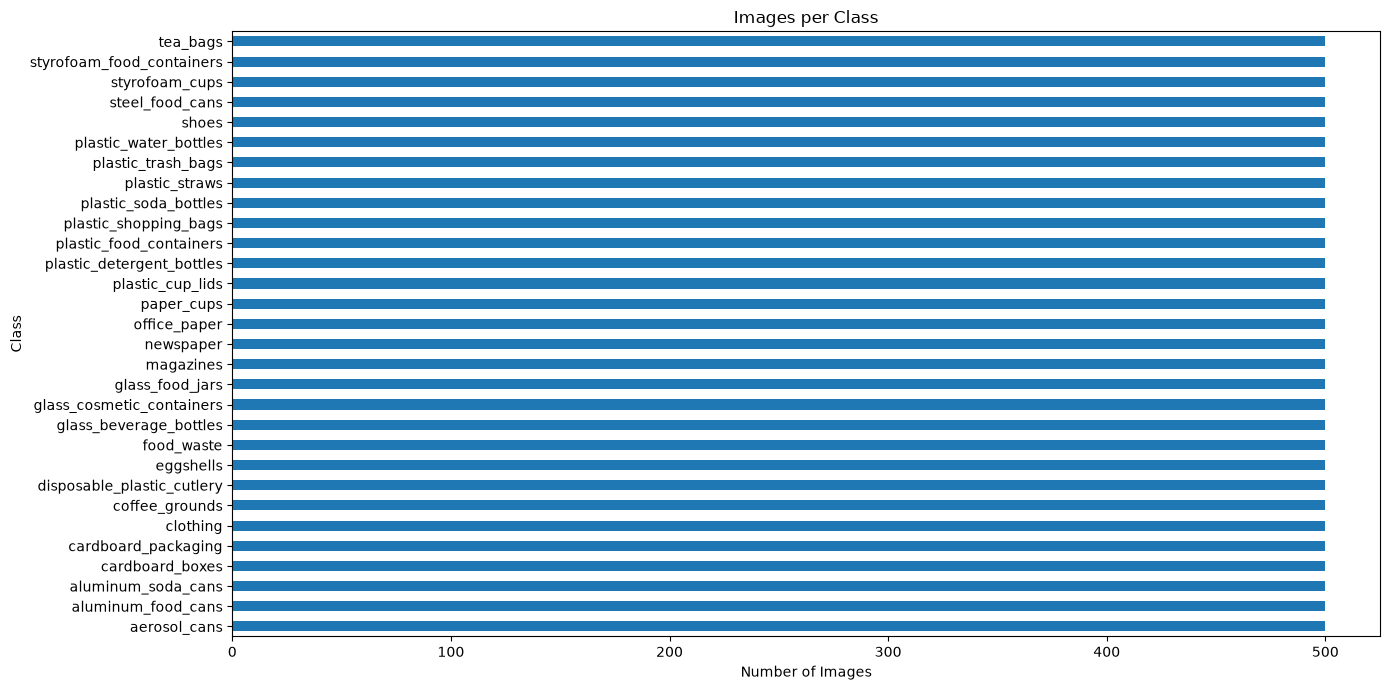

In [8]:
plt.figure(figsize=(14,7))

class_counts.sort_values().plot(kind="barh")

plt.title("Images per Class")

plt.xlabel("Number of Images")

plt.ylabel("Class")

plt.tight_layout()

plt.show()

In [9]:
sizes = []

for img_path in df["image_path"]:

    img = Image.open(img_path)

    sizes.append(img.size)

sizes = np.array(sizes)

print("Unique image sizes:", len(np.unique(sizes, axis=0)))

Unique image sizes: 1


In [10]:
size_df = pd.DataFrame(sizes, columns=["Width","Height"])

size_df.value_counts().head(10)

Width  Height
256    256       15000
Name: count, dtype: int64

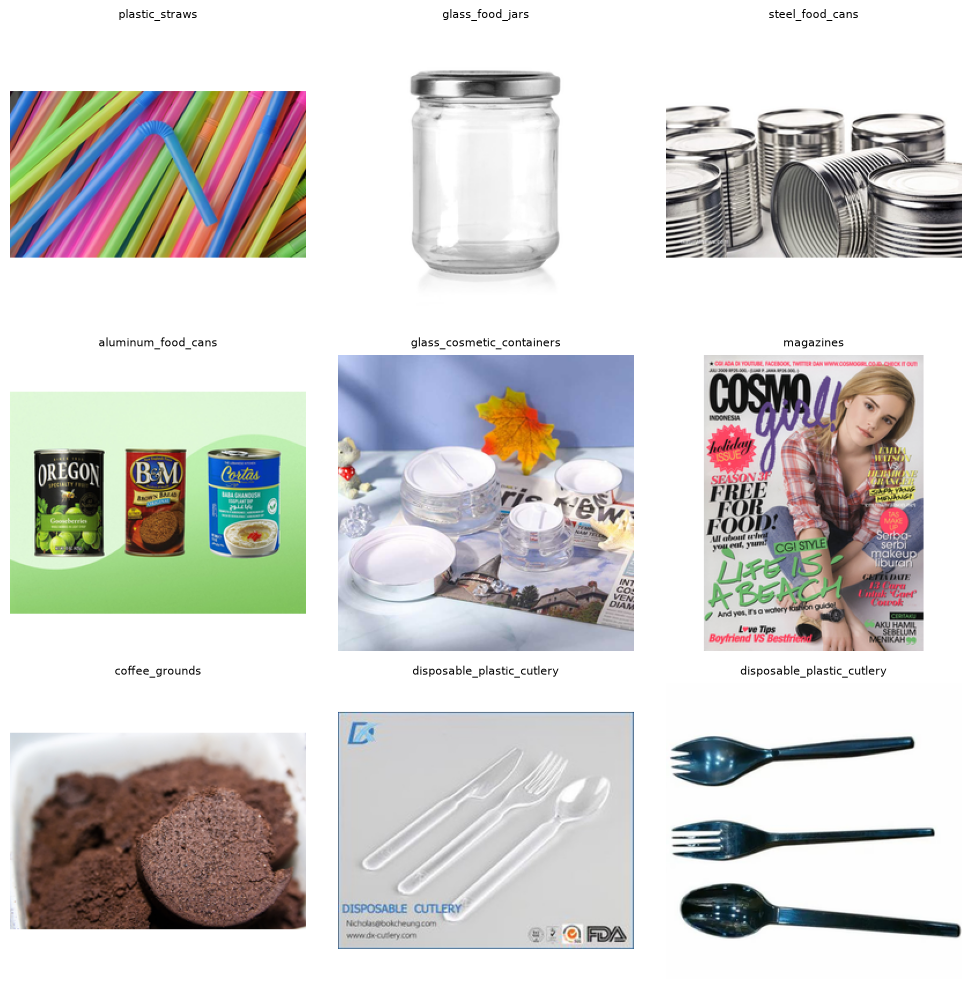

In [11]:
sample_images = df.sample(9, random_state=SEED)

plt.figure(figsize=(10,10))

for i, (_, row) in enumerate(sample_images.iterrows()):

    img = Image.open(row["image_path"])

    plt.subplot(3,3,i+1)

    plt.imshow(img)

    plt.title(row["label"], fontsize=8)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [12]:
class_names = sorted(df["label"].unique())

with open("class_names.json","w") as f:

    json.dump(class_names, f, indent=4)

print("Saved class_names.json")

Saved class_names.json


In [13]:
config = {

    "image_size": 224,

    "batch_size": 32,

    "num_classes": len(class_names)

}

with open("preprocessing_config.json","w") as f:

    json.dump(config, f, indent=4)

print(config)

{'image_size': 224, 'batch_size': 32, 'num_classes': 30}


In [14]:
for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:

    folder.mkdir(parents=True, exist_ok=True)

    for class_name in classes:

        (folder / class_name).mkdir(parents=True, exist_ok=True)

print("Directories created.")

Directories created.


In [15]:
for class_name in classes:

    class_folder = DATASET_DIR / class_name

    image_list = []

    for subfolder in class_folder.iterdir():

        if not subfolder.is_dir():
            continue

        image_list.extend(list(subfolder.glob("*.png")))

    train_imgs, temp_imgs = train_test_split(
        image_list,
        train_size=TRAIN_RATIO,
        random_state=SEED,
        shuffle=True
    )

    val_imgs, test_imgs = train_test_split(
        temp_imgs,
        test_size=0.5,
        random_state=SEED,
        shuffle=True
    )

    for img in train_imgs:
        source_folder = img.parent.name
        new_name = f"{source_folder}_{img.name}"
        shutil.copy(img, TRAIN_DIR / class_name / new_name)

    for img in val_imgs:
        source_folder = img.parent.name
        new_name = f"{source_folder}_{img.name}"
        shutil.copy(img, VAL_DIR / class_name / new_name)

    for img in test_imgs:
        source_folder = img.parent.name
        new_name = f"{source_folder}_{img.name}"
        shutil.copy(img, TEST_DIR / class_name / new_name)

print("Dataset split completed.")

Dataset split completed.


In [16]:
def count_images(folder):

    total = 0

    for c in classes:

        total += len(list((folder / c).glob("*.png")))

    return total


print("Training   :", count_images(TRAIN_DIR))
print("Validation :", count_images(VAL_DIR))
print("Test       :", count_images(TEST_DIR))

Training   : 10500
Validation : 2250
Test       : 2250


In [17]:
split_summary = []

for c in classes:

    train_count = len(list((TRAIN_DIR / c).glob("*.png")))
    val_count = len(list((VAL_DIR / c).glob("*.png")))
    test_count = len(list((TEST_DIR / c).glob("*.png")))

    split_summary.append([
        c,
        train_count,
        val_count,
        test_count
    ])

split_df = pd.DataFrame(
    split_summary,
    columns=[
        "Class",
        "Train",
        "Validation",
        "Test"
    ]
)

split_df

,Class,Train,Validation,Test
0,aerosol_cans,350,75,75
1,aluminum_food_cans,350,75,75
2,aluminum_soda_cans,350,75,75
3,cardboard_boxes,350,75,75
4,cardboard_packaging,350,75,75
5,clothing,350,75,75
6,coffee_grounds,350,75,75
7,disposable_plastic_cutlery,350,75,75
8,eggshells,350,75,75
9,food_waste,350,75,75


In [18]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Save before optimization
CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)

Found 10500 files belonging to 30 classes.
Found 2250 files belonging to 30 classes.
Found 2250 files belonging to 30 classes.


In [19]:
print(CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

['aerosol_cans', 'aluminum_food_cans', 'aluminum_soda_cans', 'cardboard_boxes', 'cardboard_packaging', 'clothing', 'coffee_grounds', 'disposable_plastic_cutlery', 'eggshells', 'food_waste', 'glass_beverage_bottles', 'glass_cosmetic_containers', 'glass_food_jars', 'magazines', 'newspaper', 'office_paper', 'paper_cups', 'plastic_cup_lids', 'plastic_detergent_bottles', 'plastic_food_containers', 'plastic_shopping_bags', 'plastic_soda_bottles', 'plastic_straws', 'plastic_trash_bags', 'plastic_water_bottles', 'shoes', 'steel_food_cans', 'styrofoam_cups', 'styrofoam_food_containers', 'tea_bags']
Number of classes: 30


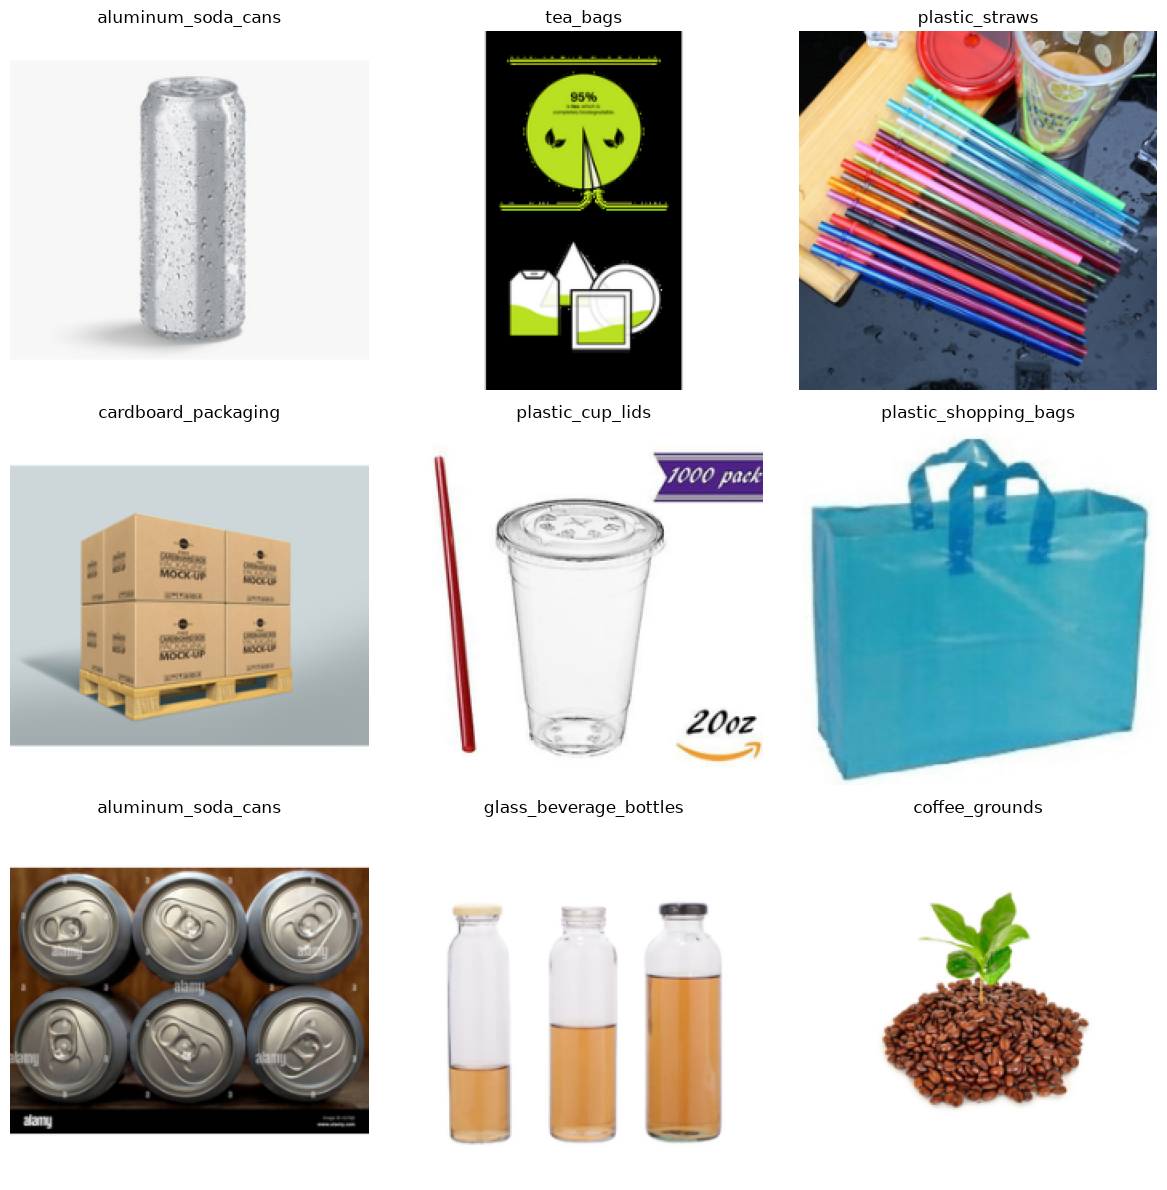

In [20]:
plt.figure(figsize=(12,12))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(CLASS_NAMES[labels[i]])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.1),

    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.RandomTranslation(
        0.1,
        0.1
    )

])

In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache()
train_ds = train_ds.shuffle(1000)
train_ds = train_ds.prefetch(AUTOTUNE)

val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)